In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('custdata.tsv', sep='\t')
cols = ['age', 'income', 'num.vehicles']
x = df[cols]
print(df.shape)
x.describe().round(2)

(1000, 11)


,age,income,num.vehicles
count,1000.00,1000.00,944.00
mean,51.70,53504.77,1.92
std,18.86,65478.07,1.10
min,0.00,-8700.00,0.00
25%,38.00,14600.00,1.00
50%,50.00,35000.00,2.00
75%,64.00,67000.00,2.00
max,146.68,615000.00,6.00


Age ranges from 0 to ~147, income has a negative minimum, and num.vehicles has missing values (count < 1000).

In [2]:
before = x.corr()
before.round(3)

,age,income,num.vehicles
age,1.000,0.027,-0.064
income,0.027,1.000,0.139
num.vehicles,-0.064,0.139,1.000


age == 0         : 3
age > 105        : 8 -> values [113.3, 123.1, 124.8, 126.7, 130.4, 136.1, 137.7, 146.7]
income < 0       : 1 -> values [-8700]
income == 0      : 78
num.vehicles NaN : 56
oldest plausible age: 93.0


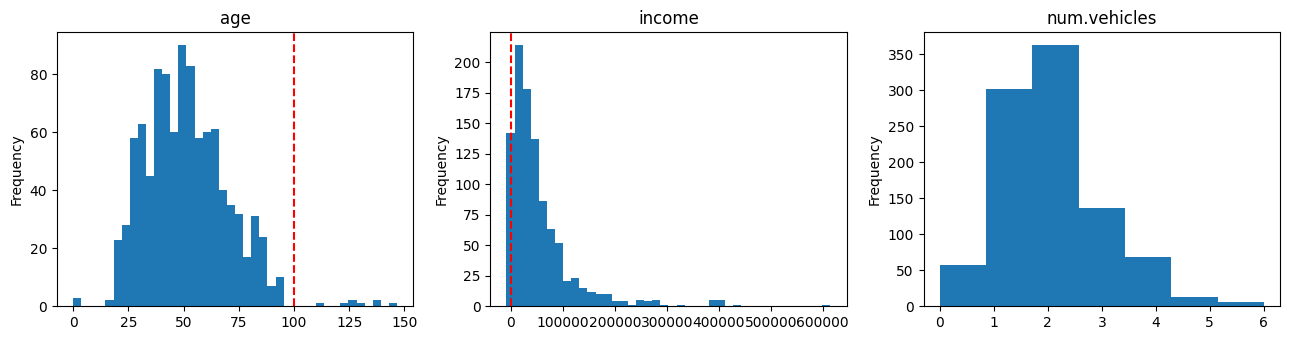

In [3]:
print('age == 0         :', (x.age == 0).sum())
print('age > 105        :', (x.age > 105).sum(), '-> values', sorted(x.age[x.age > 105].round(1)))
print('income < 0       :', (x.income < 0).sum(), '-> values', x.income[x.income < 0].tolist())
print('income == 0      :', (x.income == 0).sum(),)
print('num.vehicles NaN :', x['num.vehicles'].isna().sum())
print('oldest plausible age:', x.age[x.age <= 105].max().round(1))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
x.age.plot.hist(bins=40, ax=ax[0], title='age'); ax[0].axvline(100, color='r', ls='--')
x.income.plot.hist(bins=40, ax=ax[1], title='income'); ax[1].axvline(0, color='r', ls='--')
x['num.vehicles'].plot.hist(bins=7, ax=ax[2], title='num.vehicles')
plt.tight_layout(); plt.show()

In [4]:
valid = (x.age > 0) & (x.age <= 105) & (x.income >= 0)
clean = x[valid].dropna()

removed = pd.Series({
    'age == 0': (x.age == 0).sum(),
    'age > 105': (x.age > 105).sum(),
    'income < 0': (x.income < 0).sum(),
    'missing num.vehicles': x['num.vehicles'].isna().sum(),
})
print(removed.to_string())
print(f'\nRows: {len(x)} -> {len(clean)}  ({len(x) - len(clean)} removed)')

age == 0                 3
age > 105                8
income < 0               1
missing num.vehicles    56

Rows: 1000 -> 932  (68 removed)


### What was removed and why
I removed age = 0(3, a newborn can't be a customer and 0 is likely a placeholder), age > 105 (8, too high, many of the ages are impossible and anything over 105 is very improbable), negative income(1, not valid. You can't have a negative income), and missing `num.vehicles` (56, filling pulls correlations toward zero and understates relationships). 68 removed total.

In [5]:
after = clean.corr()
after.round(3)

,age,income,num.vehicles
age,1.000,-0.003,-0.066
income,-0.003,1.000,0.138
num.vehicles,-0.066,0.138,1.000


In [6]:
diff = (after - before).round(3)
pairs = [('age','income'), ('age','num.vehicles'), ('income','num.vehicles')]
pd.DataFrame({
    'before': [before.loc[a, b] for a, b in pairs],
    'after':  [after.loc[a, b] for a, b in pairs],
    'change': [diff.loc[a, b] for a, b in pairs],
}, index=[f'{a} ~ {b}' for a, b in pairs]).round(3)

,before,after,change
age ~ income,0.027,-0.003,-0.030
age ~ num.vehicles,-0.064,-0.066,-0.003
income ~ num.vehicles,0.139,0.138,-0.001


### Sensitivity: also drop income = 0

In [7]:
alt = x[(x.age > 0) & (x.age <= 105) & (x.income > 0)].dropna()
print('n =', len(alt))
alt.corr().round(3)

n = 879


,age,income,num.vehicles
age,1.000,-0.023,-0.072
income,-0.023,1.000,0.148
num.vehicles,-0.072,0.148,1.000


### Interpretation
Age and income are uncorrelated(r ≈ 0.00). Income has a weak positive relationship with number of vehicles (r ≈ 0.14) and age has a very weak negative relationship with vehicles (r ≈ -0.07). Neither is strong enough to be useful for prediction.